# 2장 · 토큰화 — 글을 조각으로 쪼개기 ✂️

웹 챕터 **"토큰화"** 와 짝을 이루는 실습입니다.
웹 실험실에서 방식을 바꿔봤다면, 여기서는 **토크나이저를 직접 코드로** 만들어 봅니다.
(웹과 **같은 사전·같은 결과**)

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('ch2')

## 1. 사전(vocabulary) 과 토크나이저

아주 작은 목업 사전입니다. 자주 쓰는 말은 **통째로**, 조각과 낱글자도 등록해 둡니다.
각 토큰에는 고유 **ID**(1000부터)를 매깁니다. 0 은 `[UNK]`(모르는 토큰) 전용.

In [1]:
WHOLE_WORDS   = ['나는', '밥을', '먹었다', '오늘', '날씨가', '좋다']  # 통째 단어
SUBWORD_PIECES = ['토큰', '화', '는', '재미', '있다']                 # 서브워드 조각
CHARS = list('나밥을먹었다오늘날씨가좋토큰재미있')                     # 낱글자(안전망)

# 사전: 순서대로 고유 ID (중복 제거)
VOCAB = list(dict.fromkeys(WHOLE_WORDS + SUBWORD_PIECES + CHARS))
ID = {t: 1000 + i for i, t in enumerate(VOCAB)}
WHOLE = set(WHOLE_WORDS)
MAXLEN = max(len(t) for t in VOCAB)
UNK = 0
print('사전 크기:', len(VOCAB), '| 최장 토큰 길이:', MAXLEN)

사전 크기: 28 | 최장 토큰 길이: 3


## 2. 세 가지 방식으로 쪼개기

- **단어**: 띄어쓰기로 나눔, 사전에 통째로 없으면 `[UNK]`
- **글자**: 한 글자씩
- **서브워드**: 가장 긴 조각부터 사전과 맞춰 그리디로 쪼갬(아는 말은 통째, 모르는 말은 조각)

In [2]:
def tok_word(text):
    return [(w, ID[w] if w in WHOLE else UNK) for w in text.split()]

def tok_char(text):
    return [(ch, ID.get(ch, UNK)) for w in text.split() for ch in w]

def subword_split(word):
    out, i = [], 0
    while i < len(word):
        matched = ''
        for L in range(min(MAXLEN, len(word) - i), 0, -1):
            cand = word[i:i+L]
            if cand in ID:
                matched = cand; break
        if matched:
            out.append((matched, ID[matched])); i += len(matched)
        else:
            out.append((word[i], UNK)); i += 1   # 낱글자도 없으면 UNK
    return out

def tok_subword(text):
    return [p for w in text.split() for p in subword_split(w)]

def show(pairs):
    return '  '.join(f'{t}(#{i})' if i else f'{t}[UNK]' for t, i in pairs)

## 3. 직접 토큰화해 보기

웹 실험실과 같은 문장으로 확인합니다.

In [3]:
s = '나는 밥을 먹었다'
print('문장:', s)
print(' 단어  :', show(tok_word(s)))
print(' 글자  :', show(tok_char(s)))
print(' 서브워드:', show(tok_subword(s)))
print()
print('토큰 수  → 단어:', len(tok_word(s)),
      '/ 글자:', len(tok_char(s)),
      '/ 서브워드:', len(tok_subword(s)))

문장: 나는 밥을 먹었다
 단어  : 나는(#1000)  밥을(#1001)  먹었다(#1002)
 글자  : 나(#1011)  는(#1008)  밥(#1012)  을(#1013)  먹(#1014)  었(#1015)  다(#1016)
 서브워드: 나는(#1000)  밥을(#1001)  먹었다(#1002)

토큰 수  → 단어: 3 / 글자: 7 / 서브워드: 3


## 4. 단어 단위의 약점: [UNK]

사전에 통째로 없는 문장을 단어 단위로 쪼개면 `[UNK]` 투성이가 됩니다.
반면 **서브워드**는 아는 조각으로 쪼개 `[UNK]` 없이 처리해요.

In [4]:
s2 = '토큰화는 재미있다'
print('문장:', s2)
print(' 단어  :', show(tok_word(s2)), ' ← 둘 다 UNK!')
print(' 서브워드:', show(tok_subword(s2)), ' ← UNK 없음')
print(' 글자  :', show(tok_char(s2)))
print()
print('토큰 수  → 단어:', len(tok_word(s2)),
      '/ 서브워드:', len(tok_subword(s2)),
      '/ 글자:', len(tok_char(s2)))

문장: 토큰화는 재미있다
 단어  : 토큰화는[UNK]  재미있다[UNK]  ← 둘 다 UNK!
 서브워드: 토큰(#1006)  화(#1007)  는(#1008)  재미(#1009)  있다(#1010)  ← UNK 없음
 글자  : 토(#1023)  큰(#1024)  화(#1007)  는(#1008)  재(#1025)  미(#1026)  있(#1027)  다(#1016)

토큰 수  → 단어: 2 / 서브워드: 5 / 글자: 8


## 5. 방식별 토큰 수 비교 (그래프)

같은 문장이라도 방식에 따라 토큰 수가 크게 달라집니다. 서브워드가 **절충안**이에요.

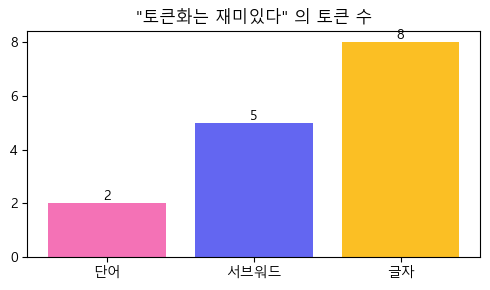

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # Windows 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

modes = ['단어', '서브워드', '글자']
vals  = [len(tok_word(s2)), len(tok_subword(s2)), len(tok_char(s2))]
plt.figure(figsize=(5, 3))
bars = plt.bar(modes, vals, color=['#f472b6', '#6366f1', '#fbbf24'])
plt.title(f'"{s2}" 의 토큰 수')
plt.bar_label(bars)
plt.tight_layout(); plt.show()

## 6. 직접 해보기 ✏️

`'오늘 날씨가 좋다'` 를 **서브워드**로 쪼개면 토큰이 몇 개일까요? 예상한 뒤 코드로 확인하세요.

In [6]:
s3 = '오늘 날씨가 좋다'
result = tok_subword(s3)
print(show(result))
print('토큰 수:', len(result))

# 세 단어 모두 사전에 통째로 있으니 서브워드도 3개, UNK 0개여야 합니다.
assert len(result) == 3, '아는 단어는 통째로 매칭됩니다!'
assert all(i != UNK for _, i in result), 'UNK 가 없어야 합니다!'
print('✅ 아는 단어는 서브워드에서도 통째로 유지됩니다.')

오늘(#1003)  날씨가(#1004)  좋다(#1005)
토큰 수: 3
✅ 아는 단어는 서브워드에서도 통째로 유지됩니다.


## 7. 더 깊이 · 미니 BPE: 사전은 어떻게 만들어지나 ✂️

지금까지는 사전을 **손으로** 만들었지만, 진짜 토크나이저의 사전은 **BPE(Byte Pair Encoding)**가
데이터에서 학습합니다. 규칙은 하나뿐이에요: **가장 자주 붙어 나오는 두 조각을 합치고, 반복한다**
(가장 좋은 것부터 집는다는 뜻에서 "탐욕(greedy)" 알고리즘이라 부릅니다).

웹 더 깊이 카드의 예제(말뭉치 `바나나 바나나 나나`)를 코드로 그대로 돌려 봅니다.

In [ ]:
from collections import Counter

corpus = ['바나나', '바나나', '나나']          # 미니 말뭉치 (웹 더 깊이 카드와 같은 예제)
tokens = [list(w) for w in corpus]             # 시작: 전부 낱글자

def pair_counts(tokens):
    """이웃한 두 조각이 몇 번 붙어 나오는지 센다."""
    c = Counter()
    for w in tokens:
        for a, b in zip(w, w[1:]):
            c[(a, b)] += 1
    return c

def apply_merge(w, m):
    """조각열 w 에서 이어 붙이면 m 이 되는 이웃 쌍을 합친다."""
    out, i = [], 0
    while i < len(w):
        if i + 1 < len(w) and w[i] + w[i + 1] == m:
            out.append(m); i += 2
        else:
            out.append(w[i]); i += 1
    return out

merges = []                                    # 학습된 병합 규칙 (순서 중요!)
while True:
    counts = pair_counts(tokens)
    if not counts:
        break
    (a, b), n = counts.most_common(1)[0]       # 가장 잦은 쌍부터 — 그래서 "탐욕(greedy)"
    if n < 2:
        break                                  # 2번도 안 나오면 그만
    merges.append(a + b)
    tokens = [apply_merge(w, a + b) for w in tokens]
    print(f'병합: ({a},{b}) {n}회 → 새 토큰 "{a+b}"   말뭉치: {tokens}')

def bpe_encode(word):
    """학습된 병합 규칙을 순서대로 적용 — 진짜 BPE 인코딩과 같은 방식."""
    w = list(word)
    for m in merges:
        w = apply_merge(w, m)
    return w

print()
print('학습된 사전 =', sorted({ch for w in corpus for ch in w} | set(merges)))
print('바나나 →', bpe_encode('바나나'), ' ← 자주 본 단어는 1토큰')
print('바나다 →', bpe_encode('바나다'), ' ← 처음 보는 단어도 [UNK] 없이 조각으로')

assert merges == ['나나', '바나나'], '병합 순서: 가장 잦은 (나,나) 3회 먼저, 다음 (바,나나) 2회'
assert bpe_encode('바나나') == ['바나나'], '흔한 단어는 통째 1토큰'
assert bpe_encode('바나다') == ['바', '나', '다'], '처음 보는 단어도 낱글자 조합으로 살아남는다'
print('\n✅ 흔한 건 짧게, 드문 건 잘게. GPT 계열의 사전도 이 반복을 수만 번 돌려 만든 것입니다.')

---
글이 **토큰 → 숫자 ID** 가 됐습니다. 하지만 ID 는 아직 '번호표'일 뿐, 뜻은 없어요.
다음 챕터(ch3 임베딩)에서 이 ID 를 **의미를 담은 숫자 벡터**로 바꿉니다. 🔢→🧭